# 🎵 Hit Song Predictor
## Exploratory Data Analysis & Data Visualization

This notebook explores the audio characteristics associated with hit and
non-hit songs using the Spotify Hit Predictor dataset covering music from
the 1960s to the 2010s.

### Objectives
- Compare the audio characteristics of hit and non-hit songs.
- Identify features associated with hit status.
- Examine relationships between musical features.
- Investigate how the characteristics of hit songs changed across decades.
- Generate insights that will guide the machine-learning stage of the project.

**Target variable:**  
- `0` = Non-Hit  
- `1` = Hit

In [ ]:
import pandas as pd
import numpy as np
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
files = glob.glob("/content/dataset-of-*.csv")
dfs = []
for file in files:
    df_temp = pd.read_csv(file)

    decade = os.path.basename(file)
    df_temp["decade"] = decade

    dfs.append(df_temp)

df = pd.concat(dfs, ignore_index=True)

print(df.shape)
df.head()

(41106, 20)


,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
0,Walking Blues,Big Joe Williams,spotify:track:1ZjN5X8LmUB67pWPgimW3B,0.509,0.277,6,-14.323,1,0.0495,0.827,0.00206,0.0756,0.640,101.157,161893,4,68.46530,7,0,dataset-of-80s.csv
1,Suddenly Last Summer,The Motels,spotify:track:4fLIM0B1WwrLux9RdnMvze,0.716,0.753,2,-5.682,1,0.0286,0.162,0.03060,0.0831,0.561,120.141,222000,4,57.71583,11,1,dataset-of-80s.csv
2,Sanctuary,Béla Fleck,spotify:track:3DwlNfiCQSdj0GOxYkR9Rq,0.360,0.542,5,-13.885,1,0.0339,0.368,0.16500,0.1160,0.803,116.831,444907,4,30.34574,17,0,dataset-of-80s.csv
3,The Wild Rover,The Pogues,spotify:track:6JyYNPLalPgGa7XnclF5FO,0.656,0.512,7,-11.872,1,0.0290,0.585,0.00000,0.0720,0.880,97.500,157893,3,50.97022,7,0,dataset-of-80s.csv
4,In The Driver's Seat,John Schneider,spotify:track:6jJi8OXF5qaFdysB6sjWIT,0.642,0.889,2,-5.620,0,0.0494,0.375,0.00000,0.1800,0.764,163.351,162293,4,33.62053,7,1,dataset-of-80s.csv


In [ ]:
#EDA
#1. Shape and analyzing last few rows
print("Shape: ")
print(df.shape)
print("Last 5 rows")
df.tail(3)

Shape: 
(41106, 20)
Last 5 rows


,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target,decade
41103,Useless Landscape,Antônio Carlos Jobim,spotify:track:2uC02PCRVM6BhAaK7dgxxp,0.361,0.0944,10,-22.663,1,0.0327,0.940,0.000178,0.115,0.139,92.472,137200,4,56.63498,6,0,dataset-of-60s.csv
41104,Vendedor De Assaí,Ary Lobo,spotify:track:0gpSUWZWNIRrEenaC1ZGk9,0.452,0.7590,4,-7.821,0,0.1750,0.658,0.000000,0.738,0.853,137.976,159107,3,28.24372,9,0,dataset-of-60s.csv
41105,Mambo Simphony - Remasterizado,Orquesta Casino De La Playa,spotify:track:5j0G0nkCSPlmSCSgXchMn3,0.554,0.2780,5,-8.386,1,0.0349,0.928,0.922000,0.136,0.428,131.401,164227,4,37.39251,8,0,dataset-of-60s.csv


In [ ]:
#2. Checking Column Types
print("Column Types: ")
print(df.dtypes)
print("\n----info----\n")
print(df.info())

Column Types: 
track                object
artist               object
uri                  object
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
duration_ms           int64
time_signature        int64
chorus_hit          float64
sections              int64
target                int64
decade               object
dtype: object

----info----

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41106 entries, 0 to 41105
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track             41106 non-null  object 
 1   artist            41106 non-null  object 
 2   uri               41106 non-null  object 
 3   danceability      41106 non-null  float64
 4   

In [ ]:
#checking for null values
print("Missing values per column")
print(df.isnull().sum())

Missing values per column
track               0
artist              0
uri                 0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_ms         0
time_signature      0
chorus_hit          0
sections            0
target              0
decade              0
dtype: int64


In [ ]:
#Describe the dataset
print("Description: ")
print(df.describe())

Description: 
       danceability        energy           key      loudness          mode  \
count  41106.000000  41106.000000  41106.000000  41106.000000  41106.000000   
mean       0.539695      0.579545      5.213594    -10.221525      0.693354   
std        0.177821      0.252628      3.534977      5.311626      0.461107   
min        0.000000      0.000251      0.000000    -49.253000      0.000000   
25%        0.420000      0.396000      2.000000    -12.816000      0.000000   
50%        0.552000      0.601000      5.000000     -9.257000      1.000000   
75%        0.669000      0.787000      8.000000     -6.374250      1.000000   
max        0.988000      1.000000     11.000000      3.744000      1.000000   

        speechiness  acousticness  instrumentalness      liveness  \
count  41106.000000  41106.000000      41106.000000  41106.000000   
mean       0.072960      0.364197          0.154416      0.201535   
std        0.086112      0.338913          0.303530      0.172959  

In [ ]:
# Clean the decade column
decade_mapping = {
    'dataset-of-60s.csv': '1960s',
    'dataset-of-70s.csv': '1970s',
    'dataset-of-80s.csv': '1980s',
    'dataset-of-90s.csv': '1990s',
    'dataset-of-00s.csv': '2000s',
    'dataset-of-10s.csv': '2010s'
}
df["decade"] = df["decade"].replace(decade_mapping)
decade_order = [
    "1960s",
    "1970s",
    "1980s",
    "1990s",
    "2000s",
    "2010s"
]

df["decade"] = pd.Categorical(
    df["decade"],
    categories=decade_order,
    ordered=True
)


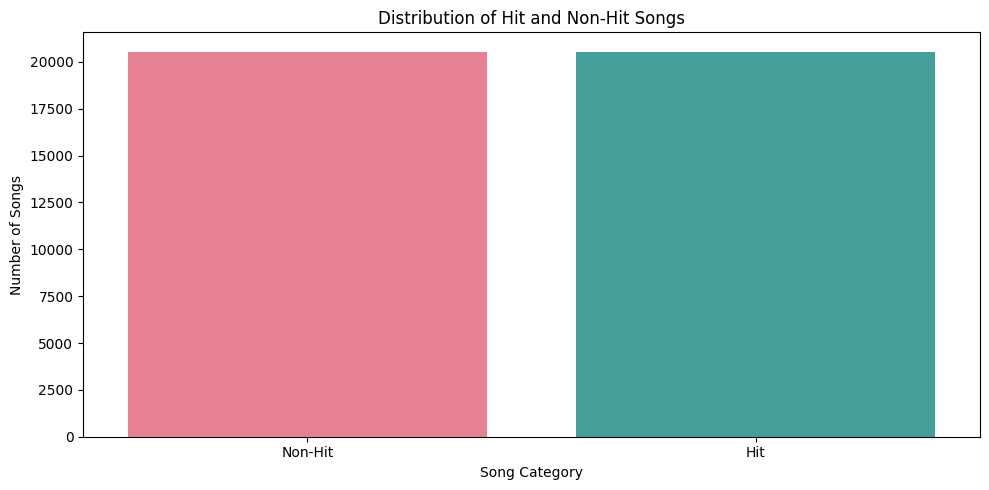

In [ ]:
#Distribution of Hit and non-Hit
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="husl",
    legend=False
)

plt.title("Distribution of Hit and Non-Hit Songs")
plt.xlabel("Song Category")
plt.ylabel("Number of Songs")
plt.xticks([0,1], ["Non-Hit", "Hit"])

plt.tight_layout()
plt.show()

In [ ]:
target_percentage = df["target"].value_counts(normalize=True) * 100
target_percentage

,proportion
target,
0,50.0
1,50.0


### Interpretation

The dataset is perfectly balanced between hit and non-hit songs, with each
class accounting for 50% of the observations. This is beneficial for
classification modelling because neither class is under-represented, reducing
the need for additional class-balancing techniques such as oversampling or
undersampling.

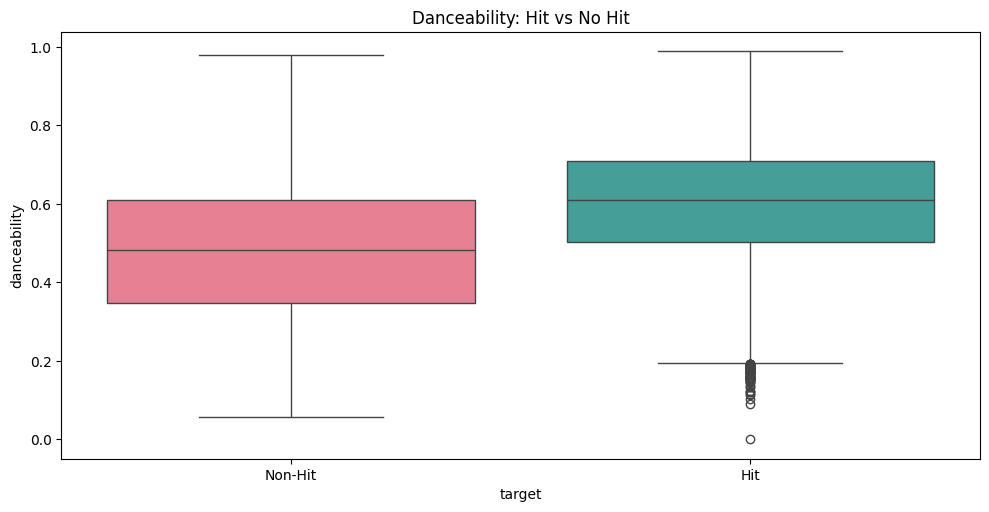

In [ ]:
#Comparison of danceability(Hit or No Hit)
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x="target",
    y="danceability",
    hue="target",
    palette="husl",
    legend=False
)
plt.xticks([0,1],["Non-Hit","Hit"])
plt.tight_layout()
plt.title("Danceability: Hit vs No Hit")
plt.show()

In [ ]:
df.groupby("target")["danceability"].mean()

,danceability
target,
0,0.478153
1,0.601237


### Interpretation

Hit songs are noticeably more danceable than non-hit songs. The average
danceability increases from approximately 0.478 for non-hits to 0.601 for
hits. The boxplot also shows an upward shift in the distribution of hit songs.
However, considerable overlap remains between the two groups, indicating that
danceability alone cannot determine whether a song becomes a hit.

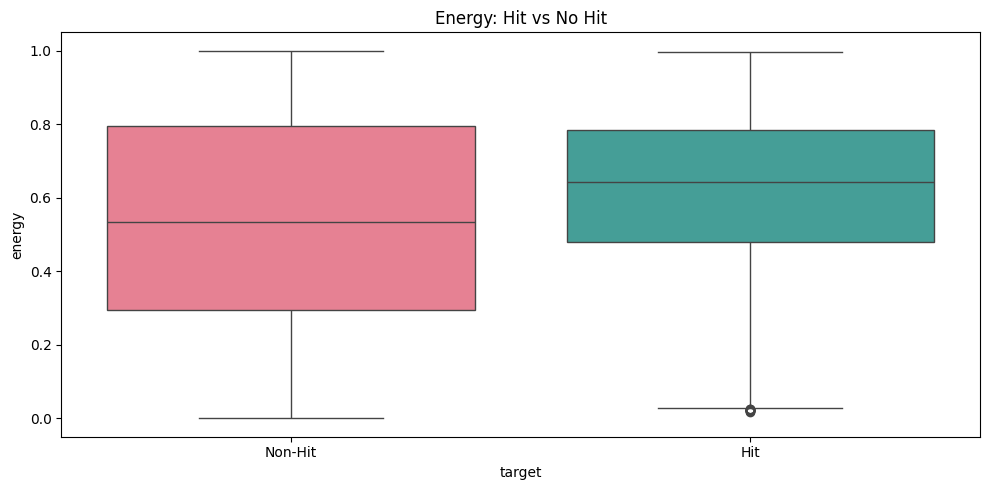

In [ ]:
#Comparison of Energy(Hit or No Hit)
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x="target",
    y="energy",
    hue="target",
    palette="husl",
    legend=False
)
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Energy: Hit vs No Hit")
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("target")["energy"].mean()

,energy
target,
0,0.534794
1,0.624296


### Interpretation

Hit songs tend to have higher energy levels than non-hit songs. Average energy
is approximately 0.624 among hits compared with 0.535 among non-hits.
Nevertheless, the distributions overlap substantially, suggesting that energy
may contribute to hit prediction but should be considered together with other
audio characteristics.

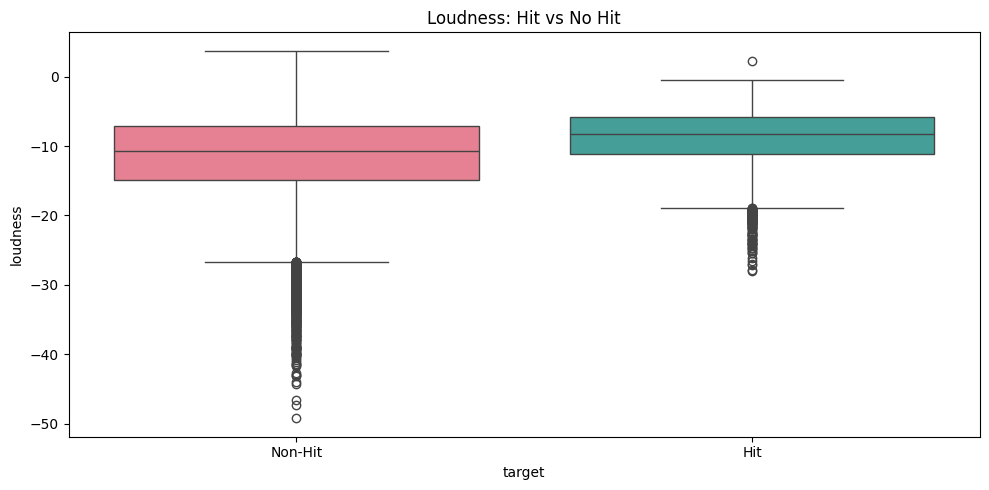

In [ ]:
#Comparison of Loudness(Hit or No Hit)
plt.figure(figsize=(10,5))
sns.boxplot(
    data=df,
    x="target",
    y="loudness",
    hue="target",
    palette="husl",
    legend=False
)
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Loudness: Hit vs No Hit")
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("target")["loudness"].mean()

,loudness
target,
0,-11.740813
1,-8.702237


### Interpretation

Hit songs are generally louder than non-hit songs. Hits have an average
loudness of approximately -8.70 dB compared with -11.74 dB for non-hits.
The difference suggests that loudness may be an important characteristic
associated with commercially successful songs. Several unusually quiet tracks
are also visible as outliers, particularly among non-hit songs.

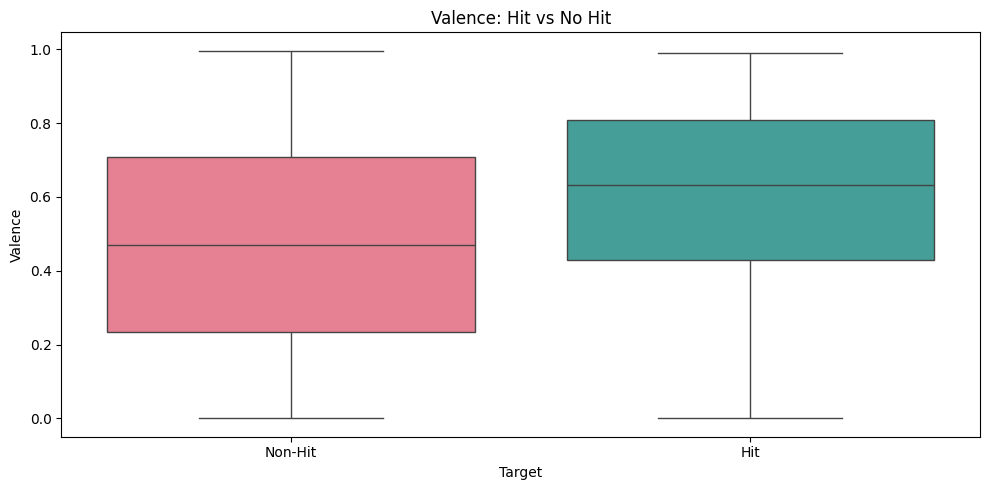

In [ ]:
#Comparison of Valence(Hit or No Hit)
plt.figure(figsize=(10,5))
sns.boxplot(
    data = df,
    x = "target",
    y = "valence",
    palette = "husl",
    legend=False,
    hue = "target"
)
plt.xlabel("Target")
plt.ylabel("Valence")
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Valence: Hit vs No Hit")
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("target")["valence"].mean()

,valence
target,
0,0.475302
1,0.609578


### Interpretation

Hit songs have higher average valence than non-hit songs, with mean values of
approximately 0.610 and 0.475 respectively. Since valence represents the
musical positivity of a track, this suggests that more positive-sounding songs
are more common among hits in this dataset. However, the overlapping
distributions indicate that successful songs can occur across a wide range of
emotional characteristics.

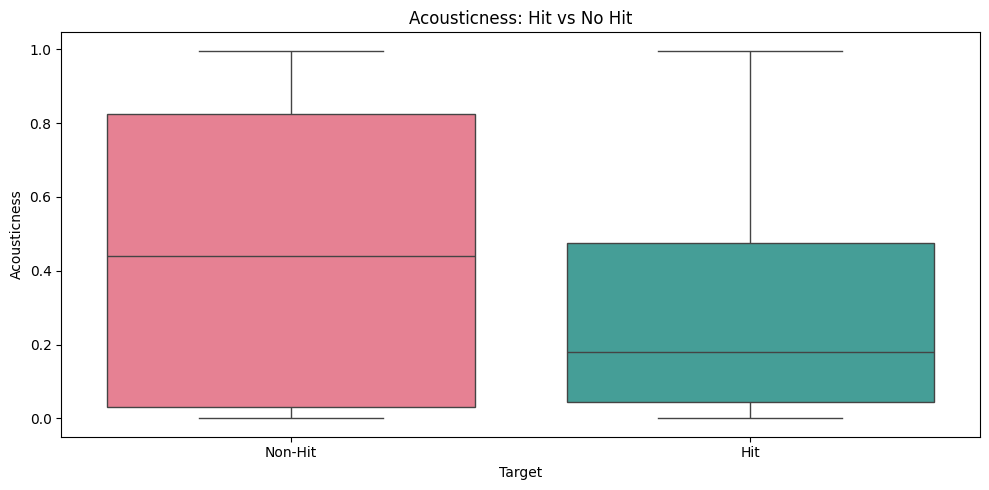

In [ ]:
#Comparison of acousticness(Hit or No Hit)
plt.figure(figsize=(10,5))
sns.boxplot(
    data = df,
    x = "target",
    y = "acousticness",
    palette = "husl",
    hue = "target",
    legend = False
)
plt.xlabel("Target")
plt.ylabel("Acousticness")
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Acousticness: Hit vs No Hit")
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("target")["acousticness"].mean()

,acousticness
target,
0,0.447581
1,0.280814


### Interpretation

Non-hit songs show substantially higher acousticness than hit songs. Average
acousticness is approximately 0.448 for non-hits compared with 0.281 for hits.
This indicates a negative relationship between acousticness and hit status in
this dataset, although the broad distributions show that acoustic songs can
still become successful.

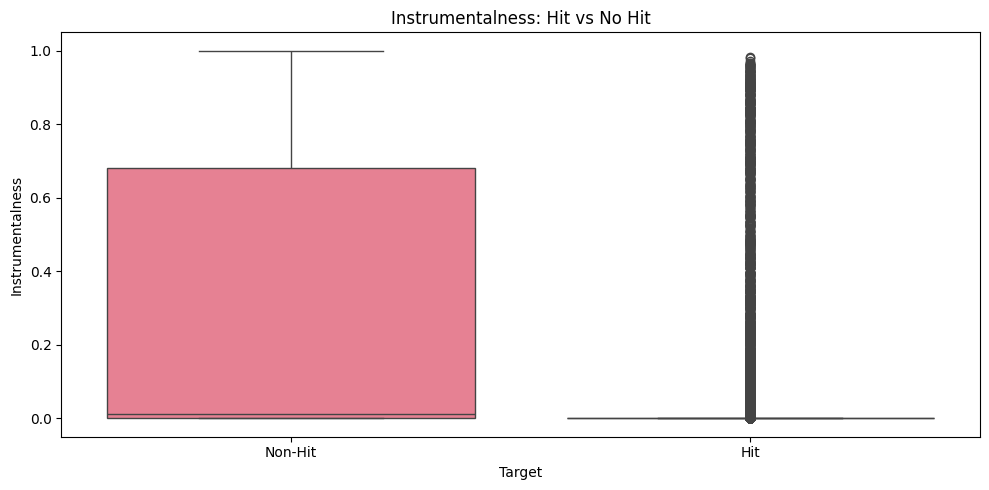

In [ ]:
#Comparison of instrumentalness(Hit or No Hit)
plt.figure(figsize=(10,5))
sns.boxplot(
    data = df,
    x = "target",
    y = "instrumentalness",
    palette = "husl",
    hue = "target",
    legend = False
)
plt.xlabel("Target")
plt.ylabel("Instrumentalness")
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Instrumentalness: Hit vs No Hit")
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("target")["instrumentalness"].mean()

,instrumentalness
target,
0,0.278145
1,0.030687


### Interpretation

Instrumentalness shows one of the clearest differences between hits and
non-hits. Non-hit songs have an average instrumentalness of approximately
0.278, while hit songs average only 0.031. Most hit songs are concentrated
close to zero instrumentalness, although some highly instrumental hits are
present as outliers. This suggests that vocal-oriented tracks are considerably
more common among hit songs in this dataset.

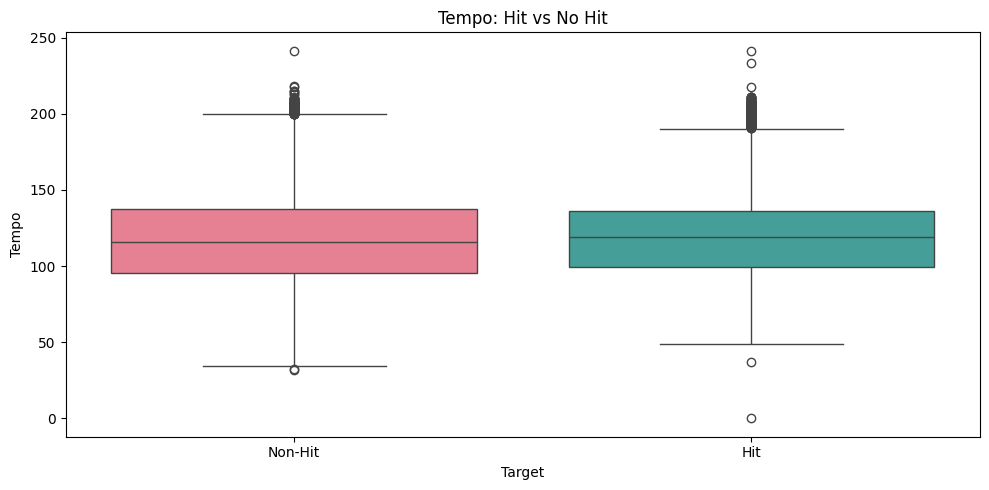

In [ ]:
#Comparison of tempo(Hit or No Hit)
plt.figure(figsize = (10,5))
sns.boxplot(
    data = df,
    x = "target",
    y = "tempo",
    palette="husl",
    hue = "target",
    legend = False
)
plt.xlabel("Target")
plt.ylabel("Tempo")
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Tempo: Hit vs No Hit")
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("target")["tempo"].mean()

,tempo
target,
0,118.388219
1,120.288280


### Interpretation

Tempo shows relatively little difference between hits and non-hits. The
average tempo is approximately 120.29 BPM for hits and 118.39 BPM for
non-hits, and the two distributions strongly overlap. Therefore, tempo by
itself appears to have limited ability to distinguish hit songs from
non-hits.

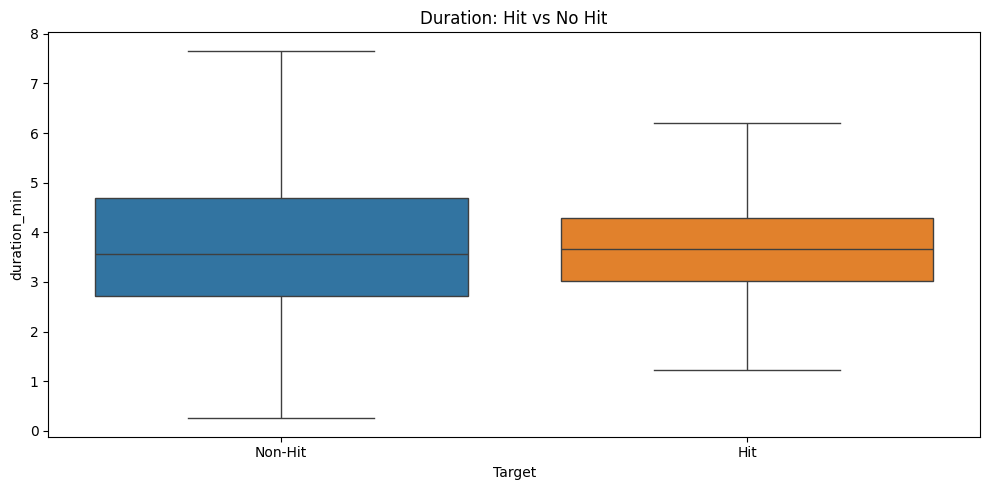

In [ ]:
#Comparison of duration(Hit or No Hit)
df["duration_min"] = df["duration_ms"] / 60000
plt.figure(figsize = (10,5))
sns.boxplot(
    data=df,
    x="target",
    y="duration_min",
    hue="target",
    legend=False,
    showfliers=False
)
plt.xlabel("Target")
plt.ylabel("duration_min")
plt.xticks([0,1],["Non-Hit","Hit"])
plt.title("Duration: Hit vs No Hit")
plt.tight_layout()
plt.show()


In [ ]:
df["duration_min"].describe()

,duration_min
count,41106.000000
mean,3.914626
std,1.982790
min,0.252800
25%,2.882129
50%,3.631783
75%,4.446217
max,69.503783


### Interpretation

Summary statistics reveal several extreme-duration tracks, including tracks
lasting far longer than typical songs. The boxplot hides these outliers to
make the main distribution easier to interpret, but they should be
investigated before modelling rather than removed automatically.

Distribution of important audio features

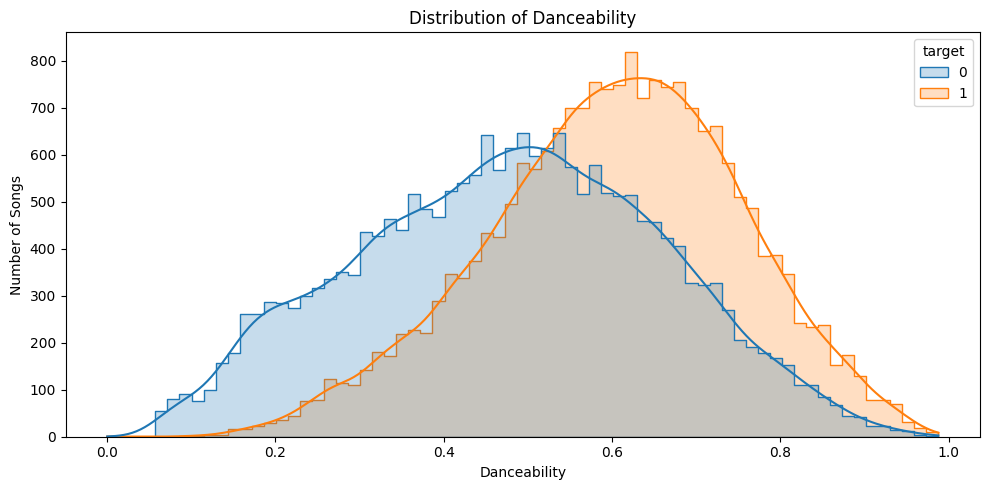

In [ ]:
#Danceability
plt.figure(figsize=(10,5))
sns.histplot(
    data=df,
    x="danceability",
    hue="target",
    kde=True,
    element="step"
)
plt.xlabel("Danceability")
plt.ylabel("Number of Songs")
plt.title("Distribution of Danceability")
plt.tight_layout()
plt.show()

### Interpretation

The distribution confirms the pattern observed in the boxplot. Hit songs are
more concentrated at higher danceability values, particularly around the
0.6–0.7 range, while non-hits are more heavily represented at lower values.
The distributions still overlap considerably, reinforcing that danceability
is informative but cannot independently classify a song as a hit.

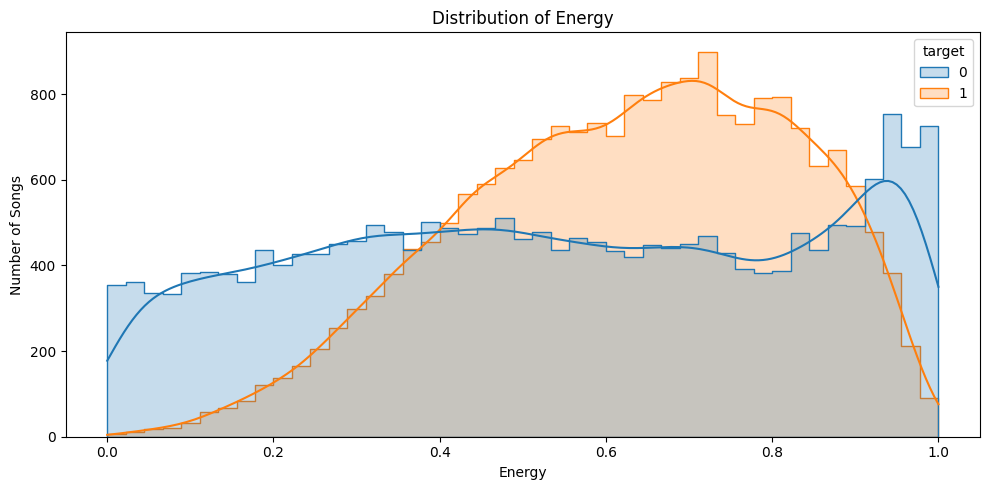

In [ ]:
#Energy
plt.figure(figsize=(10,5))
sns.histplot(
    data=df,
    x="energy",
    hue="target",
    kde=True,
    element="step"
)
plt.xlabel("Energy")
plt.ylabel("Number of Songs")
plt.title("Distribution of Energy")
plt.tight_layout()
plt.show()

### Interpretation

Hit songs are more concentrated toward medium-to-high energy levels, whereas
non-hit songs are distributed more broadly and include a larger proportion of
low-energy tracks. However, there is substantial overlap at moderate and high
energy levels, indicating that energy should be combined with other features
for prediction.

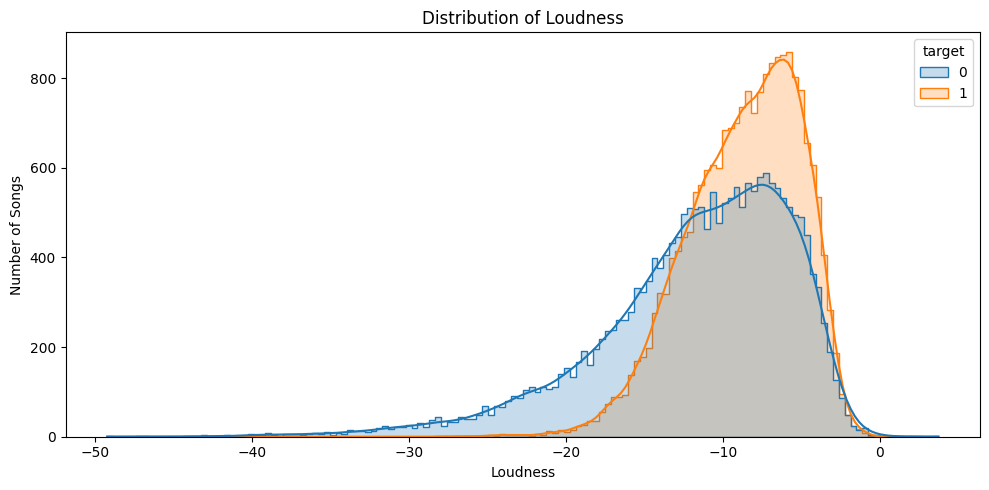

In [ ]:
#loudness
plt.figure(figsize=(10,5))
sns.histplot(
    data=df,
    x="loudness",
    hue="target",
    kde=True,
    element="step"
)
plt.xlabel("Loudness")
plt.ylabel("Number of Songs")
plt.title("Distribution of Loudness")
plt.tight_layout()
plt.show()

### Interpretation

The loudness distribution for hit songs is shifted toward less negative
values, indicating that hit songs tend to be louder. Non-hit songs display a
much longer tail toward very quiet recordings. The overlap between the two
distributions nevertheless shows that loudness is associated with, rather
than determinative of, hit status.

Hit vs Non-Hit comparison table

In [ ]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_min",
    "chorus_hit",
    "sections"
]

comparison = df.groupby("target")[features].mean().T

comparison.columns = ["Non-Hit", "Hit"]

comparison

,Non-Hit,Hit
danceability,0.478153,0.601237
energy,0.534794,0.624296
loudness,-11.740813,-8.702237
speechiness,0.076477,0.069444
acousticness,0.447581,0.280814
instrumentalness,0.278145,0.030687
liveness,0.210432,0.192637
valence,0.475302,0.609578
tempo,118.388219,120.288280
duration_min,4.060993,3.768259


Correlation Heatmap


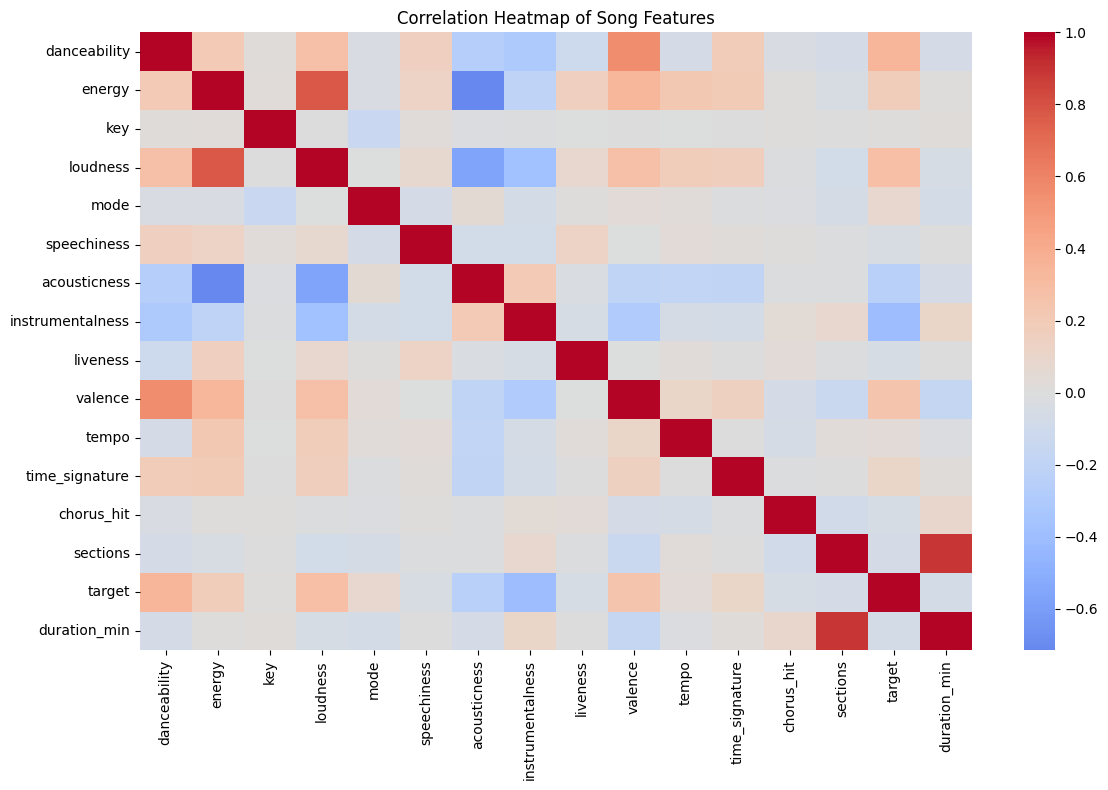

In [ ]:
numeric_df = (df.select_dtypes(include=np.number).drop(columns=["duration_ms"]))
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=False,
    center=0,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Song Features")
plt.tight_layout()
plt.show()

### Interpretation

The correlation heatmap reveals relationships both between audio features and
with the target variable. Some features, particularly energy and loudness,
show noticeable relationships with one another, suggesting that related audio
characteristics may contain overlapping information. No individual feature
shows an overwhelmingly strong positive relationship with hit status,
supporting the use of multivariate machine-learning models.

In [ ]:
#correlation with target
target_corr = (
    numeric_df.corr()["target"].sort_values(ascending = False)
)
target_corr

,target
target,1.000000
danceability,0.346097
loudness,0.286034
valence,0.251147
energy,0.177142
time_signature,0.104884
mode,0.079614
tempo,0.032649
key,0.009883
speechiness,-0.040835


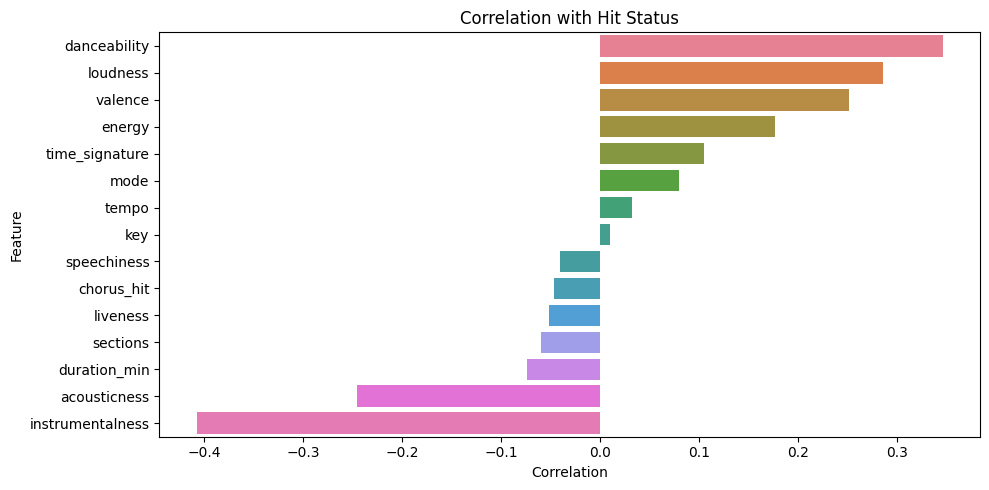

In [ ]:
#Visualize correlations with Hit status
target_corr = target_corr.drop("target")

plt.figure(figsize=(10, 5))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    hue=target_corr.index,
    palette="husl",
    legend=False
)

plt.title("Correlation with Hit Status")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Interpretation

Instrumentalness has the strongest individual relationship with hit status,
showing a negative correlation of approximately -0.408. Danceability has the
strongest positive relationship at approximately +0.346, followed by
loudness (+0.286) and valence (+0.251). Acousticness also shows a meaningful
negative relationship (-0.246). In contrast, tempo (+0.033) and key (+0.010)
have very weak relationships with the target. These results suggest that some
audio characteristics are useful predictors, although no single feature is
strong enough to explain hit status by itself.

Interactions between Features


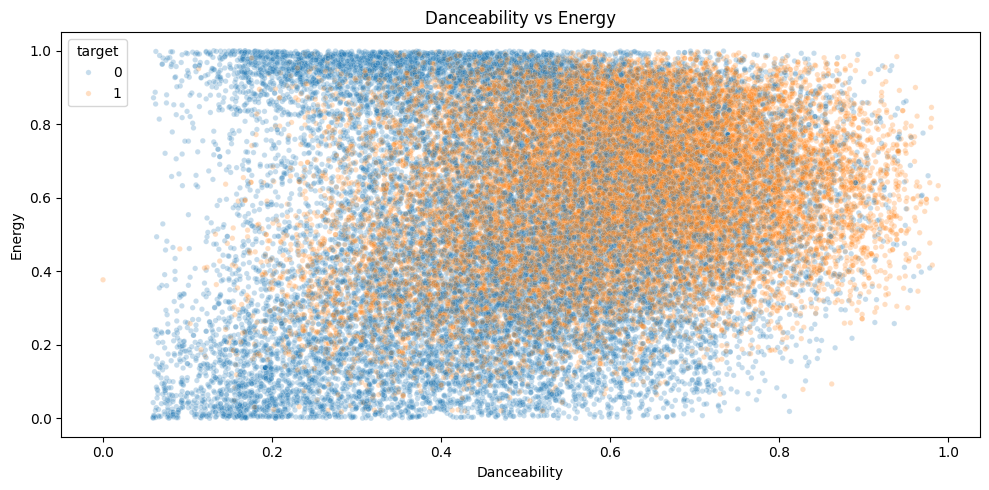

In [ ]:
# Danceability vs Energy
plt.figure(figsize = (10,5))
sns.scatterplot(
    data=df,
    x="danceability",
    y="energy",
    hue="target",
    alpha=0.25,
    s=15
)
plt.xlabel("Danceability")
plt.ylabel("Energy")
plt.title("Danceability vs Energy")
plt.tight_layout()
plt.show()

### Interpretation

Hit songs appear more frequently in the medium-to-high danceability region,
while non-hits are more widely represented at lower danceability values.
However, the extensive overlap between hits and non-hits shows that the
combination of danceability and energy alone does not provide a clear
classification boundary. This supports the need for a model that considers
multiple features simultaneously.

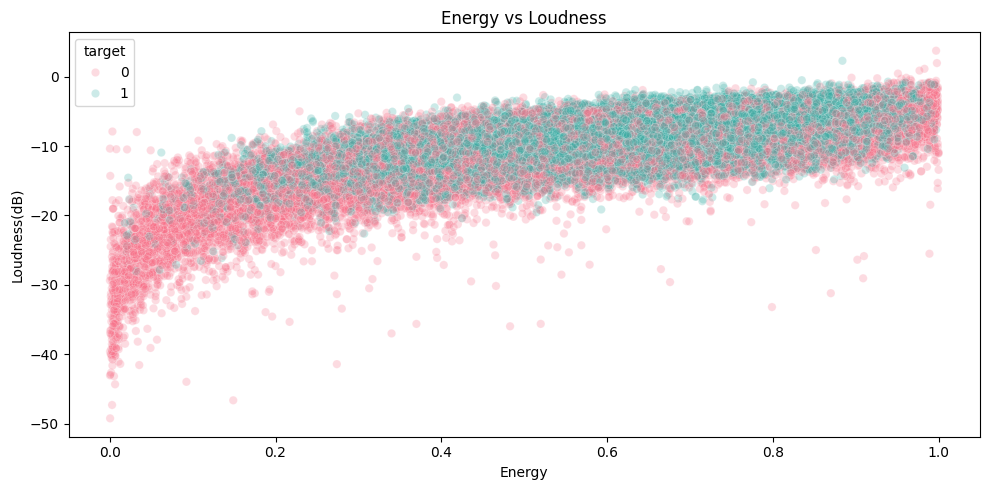

In [ ]:
# Energy vs Loudness
plt.figure(figsize = (10,5))
sns.scatterplot(
    data = df,
    x = "energy",
    y = "loudness",
    hue = "target",
    palette = "husl",
    alpha = 0.25
)
plt.xlabel("Energy")
plt.ylabel("Loudness(dB)")
plt.title("Energy vs Loudness")
plt.tight_layout()
plt.show()

### Interpretation

Energy and loudness display a clear positive relationship: higher-energy songs
generally have higher loudness values. Hit songs are more concentrated within
the higher-energy and louder region, although substantial overlap with
non-hits remains. The strong relationship between these two predictors should
also be considered when interpreting feature importance in later models.

Class Balance by decade

In [ ]:
df["decade"].unique()

['1980s', '2000s', '1970s', '2010s', '1990s', '1960s']
Categories (6, object): ['1960s' < '1970s' < '1980s' < '1990s' < '2000s' < '2010s']

In [ ]:
hit_rate_decade = (
    df.groupby("decade")["target"]
    .mean()
    .reset_index()
)

hit_rate_decade["hit_rate"] = hit_rate_decade["target"] * 100

hit_rate_decade

,decade,target,hit_rate
0,1960s,0.5,50.0
1,1970s,0.5,50.0
2,1980s,0.5,50.0
3,1990s,0.5,50.0
4,2000s,0.5,50.0
5,2010s,0.5,50.0


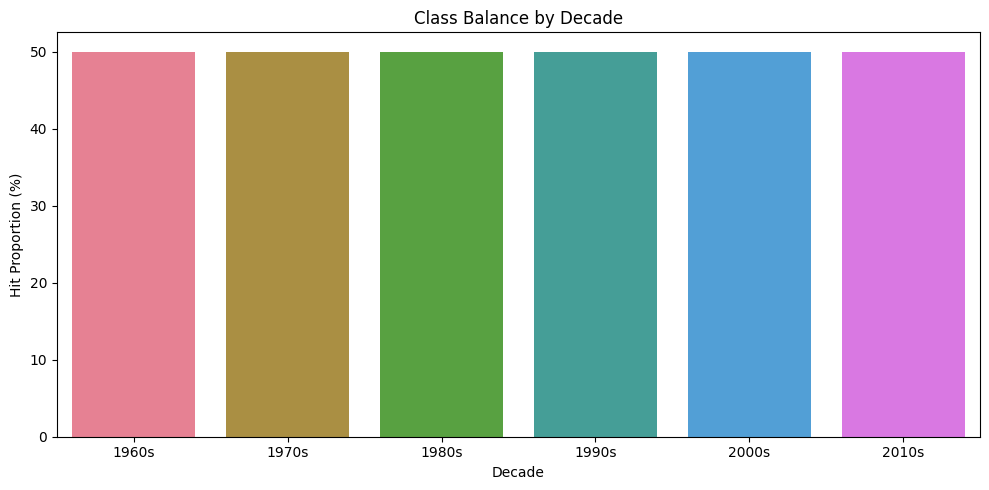

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=hit_rate_decade,
    x="decade",
    y="hit_rate",
    hue="decade",
    palette="husl",
    legend=False
)

plt.xlabel("Decade")
plt.ylabel("Hit Proportion (%)")
plt.title("Class Balance by Decade")

plt.tight_layout()
plt.show()

### Interpretation

Each decade contains an equal proportion of hit and non-hit observations,
with a 50% hit rate in the dataset. This reflects the balanced construction
of the dataset rather than the historical probability of a song becoming a
hit. The result confirms that class balance is maintained across decades,
which is useful for comparing musical characteristics over time.

Over Time comparisons


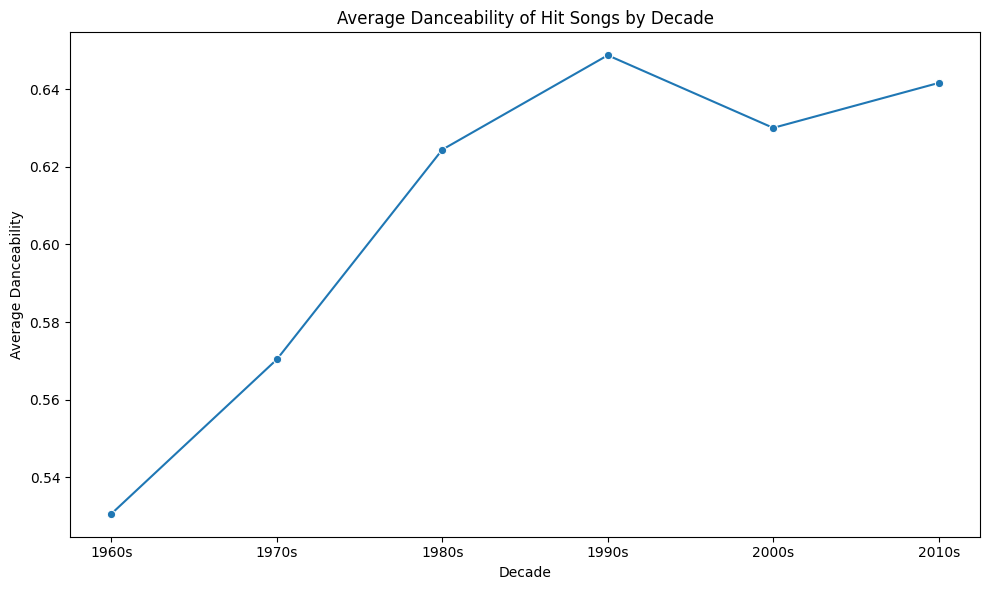

In [ ]:
#Danceability Over Time
hits = df[df["target"] == 1].copy()
decade_order = [
    "1960s",
    "1970s",
    "1980s",
    "1990s",
    "2000s",
    "2010s"
]

hits["decade"] = pd.Categorical(
    hits["decade"],
    categories=decade_order,
    ordered=True
)

# Calculate average danceability of hit songs by decade
dance_by_decade = (
    hits.groupby("decade", observed=True)["danceability"]
    .mean()
    .reset_index()
    .sort_values("decade")
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=dance_by_decade,
    x="decade",
    y="danceability",
    marker="o"
)

plt.title("Average Danceability of Hit Songs by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Danceability")

plt.tight_layout()
plt.show()

### Interpretation

The average danceability of hit songs generally increased over time, rising
from approximately 0.531 in the 1960s to 0.649 in the 1990s. It declined
slightly during the 2000s before increasing again to approximately 0.642 in
the 2010s. This suggests that danceability became a more prominent
characteristic of hit songs over the decades represented in the dataset.

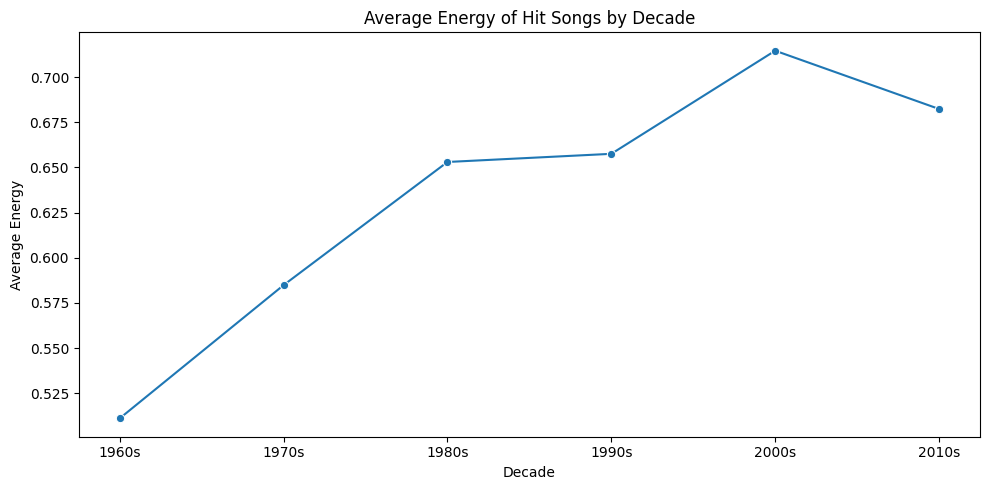

In [ ]:
energy_by_decade = (
    hits.groupby("decade", observed=True)["energy"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=energy_by_decade,
    x="decade",
    y="energy",
    marker="o"
)

plt.title("Average Energy of Hit Songs by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Energy")
plt.tight_layout()
plt.show()

### Interpretation

Hit songs became progressively more energetic from the 1960s through the
2000s. Average energy increased from approximately 0.511 in the 1960s to a
peak of 0.715 in the 2000s, followed by a modest decline to 0.682 in the
2010s. The overall pattern indicates a substantial historical shift toward
higher-energy hit music.

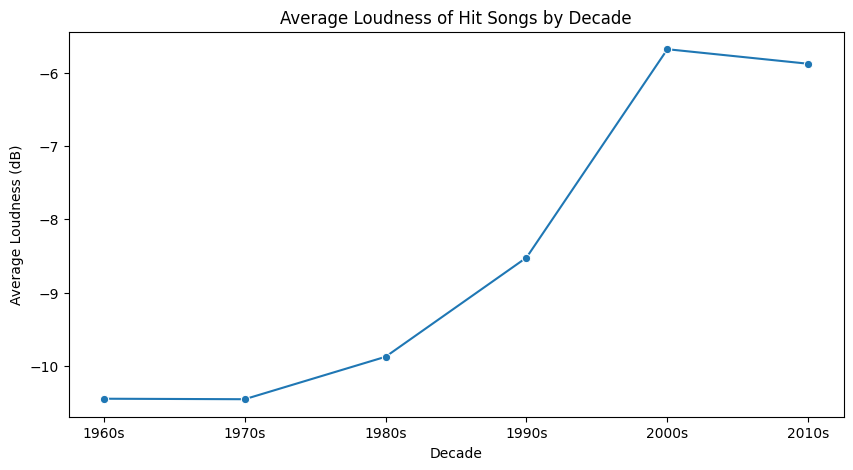

In [ ]:
loudness_by_decade = (
    hits.groupby("decade",observed=True)["loudness"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=loudness_by_decade,
    x="decade",
    y="loudness",
    marker="o"
)

plt.title("Average Loudness of Hit Songs by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Loudness (dB)")

plt.show()

### Interpretation

Hit songs generally became louder across successive decades, with the most
substantial change occurring between the earlier decades and modern music.
Although there are some fluctuations, the overall trend moves toward less
negative loudness values. This indicates a historical shift in the production
characteristics of commercially successful music.

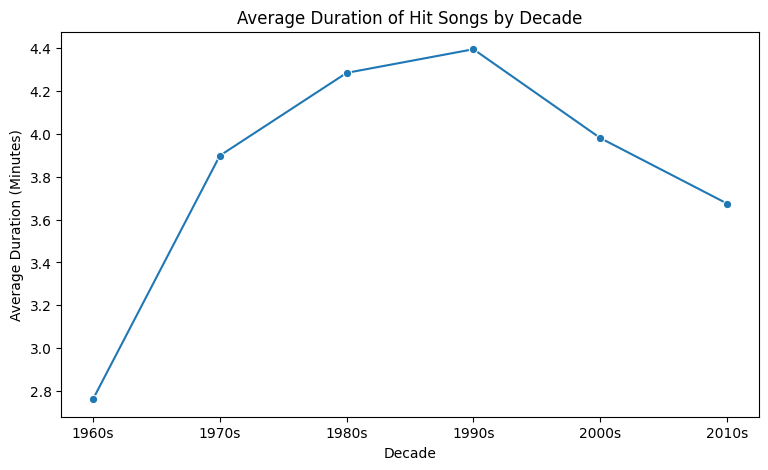

In [ ]:
duration_by_decade = (
    hits.groupby("decade",observed=True)["duration_min"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=duration_by_decade,
    x="decade",
    y="duration_min",
    marker="o"
)

plt.title("Average Duration of Hit Songs by Decade")
plt.xlabel("Decade")
plt.ylabel("Average Duration (Minutes)")

plt.show()

### Interpretation

The average duration of hit songs increased considerably from approximately
2.76 minutes in the 1960s to a peak of about 4.40 minutes in the 1990s.
Average duration then declined to approximately 3.98 minutes in the 2000s
and 3.68 minutes in the 2010s. This suggests that hit-song length has changed
substantially over time rather than following a constant pattern.

Comparison of hit Characteristics by decades


In [ ]:
decade_summary = (
    hits.groupby("decade",observed=True)[
        [
            "danceability",
            "energy",
            "valence",
            "acousticness",
            "instrumentalness",
            "tempo",
            "duration_min"
        ]
    ]
    .mean()
)

decade_summary.round(3)

,danceability,energy,valence,acousticness,instrumentalness,tempo,duration_min
decade,,,,,,,
1960s,0.531,0.511,0.663,0.537,0.050,118.743,2.761
1970s,0.570,0.585,0.665,0.341,0.048,119.704,3.899
1980s,0.624,0.653,0.657,0.205,0.028,121.868,4.285
1990s,0.649,0.658,0.582,0.170,0.030,117.807,4.396
2000s,0.630,0.715,0.554,0.148,0.009,120.284,3.981
2010s,0.642,0.682,0.494,0.162,0.006,123.525,3.675


### Key Changes Across Decades

The characteristics of hit songs changed substantially across the six decades.
Danceability and energy generally increased, while acousticness and
instrumentalness declined considerably. Valence also decreased over time,
indicating that more recent hits in this dataset are not necessarily more
positive-sounding despite becoming more energetic and danceable. Song
duration increased from the 1960s through the 1990s before declining again
during the 2000s and 2010s. These patterns indicate that the characteristics
associated with successful music are not static and should be considered when
developing a hit-prediction model.

## EDA Summary

The exploratory analysis identified several meaningful differences between
hit and non-hit songs. Hit songs tend to be more danceable, energetic,
positive in valence, and louder, while exhibiting substantially lower
acousticness and instrumentalness.

Among individual features, instrumentalness showed the strongest negative
relationship with hit status, while danceability showed the strongest positive
relationship. Tempo, by contrast, showed very little association with whether
a song was a hit.

The analysis also revealed substantial overlap between hit and non-hit songs
across individual audio features. This indicates that no single characteristic
is sufficient to determine commercial success and supports the use of
multivariate machine-learning models.

The decade analysis further demonstrated that the characteristics of hit songs
have changed over time. Hit songs generally became more danceable and energetic,
while acousticness and instrumentalness declined. Song duration also followed
a changing historical pattern rather than remaining constant.

These findings provide the foundation for the next stage: building and
evaluating machine-learning models to predict hit status from multiple audio
characteristics simultaneously.